In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../data/raw")

sales = pd.read_csv(DATA_DIR / "sales_train_validation.csv")
calendar = pd.read_csv(DATA_DIR / "calendar.csv")

day_cols = [col for col in sales.columns if col.startswith("d_")]

print(f"Number of SKUs/store series: {len(sales):,}")
print(f"Number of sales days: {len(day_cols):,}")

Number of SKUs/store series: 30,490
Number of sales days: 1,913


In [3]:
prices = pd.read_csv(DATA_DIR / "sell_prices.csv")

In [4]:
# Melt sales from wide to long
id_vars = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
sales_long = sales.melt(
    id_vars=id_vars,
    var_name='d',
    value_name='sold'
)

# Merge with calendar to get real dates
sales_long = sales_long.merge(
    calendar[['d', 'date', 'wm_yr_wk', 'weekday', 'month', 'year',
              'event_name_1', 'event_type_1', 'snap_CA', 'snap_TX', 'snap_WI']],
    on='d', how='left'
)
sales_long['date'] = pd.to_datetime(sales_long['date'])

print(sales_long.shape)  
sales_long.head()

(58327370, 18)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sold,date,wm_yr_wk,weekday,month,year,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,2011,NaN,NaN,0,0,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,2011,NaN,NaN,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,2011,NaN,NaN,0,0,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,2011,NaN,NaN,0,0,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,2011,NaN,NaN,0,0,0


In [5]:
print(f"{sales_long.memory_usage(deep=True).sum() / 1e9:.2f} GB")

cat_cols = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id',
            'd', 'weekday', 'event_name_1', 'event_type_1']
for col in cat_cols:
    sales_long[col] = sales_long[col].astype('category')

sales_long['sold'] = sales_long['sold'].astype('int32')

print(f"{sales_long.memory_usage(deep=True).sum() / 1e9:.2f} GB")  

12.93 GB
4.26 GB


Overall Sales Trend

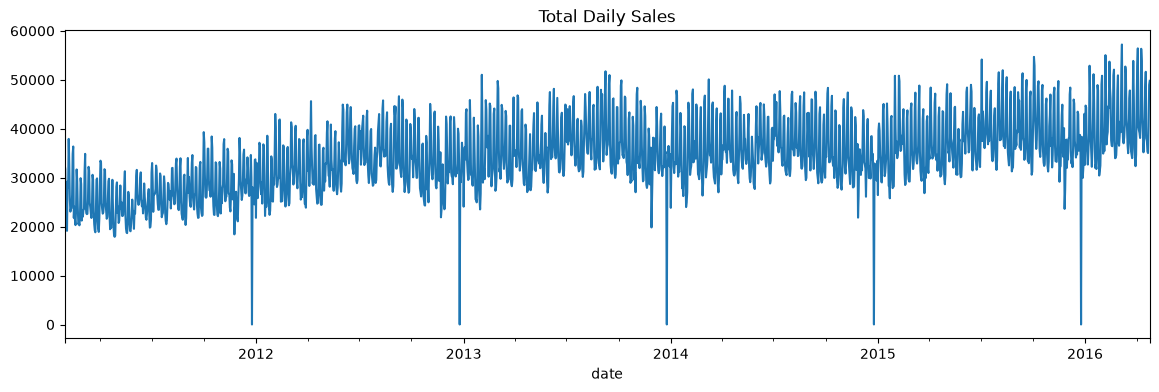

In [6]:
import matplotlib.pyplot as plt

daily_total = sales_long.groupby('date', observed=True)['sold'].sum()
daily_total.plot(figsize=(14, 4), title='Total Daily Sales')
plt.show()

Intermittency Rate

In [7]:
zero_pct = (sales_long['sold'] == 0).mean()
print(f"Zero-sale rows: {zero_pct:.1%}")

sales_long.groupby('cat_id', observed=True)['sold'].apply(lambda x: (x == 0).mean())

Zero-sale rows: 68.2%


cat_id
FOODS        0.620212
HOBBIES      0.772801
HOUSEHOLD    0.717696
Name: sold, dtype: float64

Individual SKU Examples

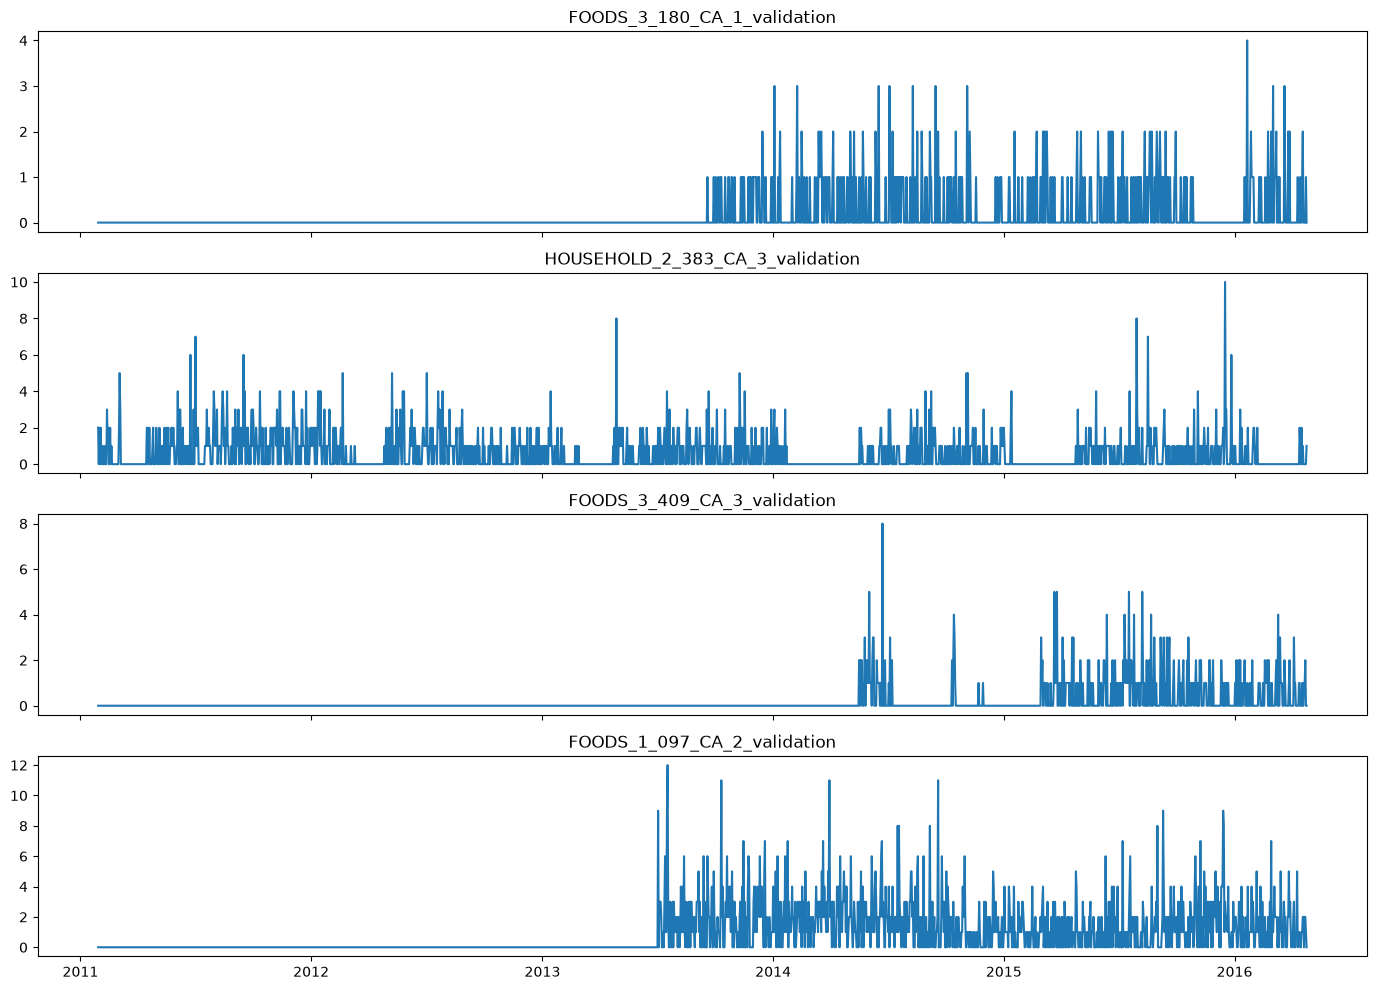

In [8]:
sample_ids = sales_long['id'].drop_duplicates().sample(4, random_state=42)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, sku in zip(axes, sample_ids):
    subset = sales_long[sales_long['id'] == sku].sort_values('date')
    ax.plot(subset['date'], subset['sold'])
    ax.set_title(sku)
plt.tight_layout()
plt.show()

In [9]:
zero_days = daily_total[daily_total == 0].index
print(zero_days)
calendar[calendar['date'].isin(zero_days)][['date', 'event_name_1', 'event_type_1']]

DatetimeIndex([], dtype='datetime64[us]', name='date', freq=None)


,date,event_name_1,event_type_1


In [10]:
print(daily_total.nsmallest(10))

date
2012-12-25       11
2011-12-25       13
2015-12-25       14
2013-12-25       20
2014-12-25       20
2011-04-27    17929
2011-04-26    18113
2011-04-28    18145
2011-11-24    18427
2011-05-19    18684
Name: sold, dtype: int32


In [11]:
import pandas as pd

for yr in [2011, 2012, 2013, 2014, 2015]:
    xmas = pd.Timestamp(year=yr, month=12, day=25)
    if xmas in daily_total.index:
        print(xmas.date(), "→", daily_total.loc[xmas])

2011-12-25 → 13
2012-12-25 → 11
2013-12-25 → 20
2014-12-25 → 20
2015-12-25 → 14


In [12]:
sales_long['is_store_closed'] = (
    (sales_long['date'].dt.month == 12) & (sales_long['date'].dt.day == 25)
).astype('int8')

In [13]:
release = prices.groupby(['store_id', 'item_id'], observed=True)['wm_yr_wk'].min().reset_index()
release.columns = ['store_id', 'item_id', 'release_wk']

sales_long = sales_long.merge(release, on=['store_id', 'item_id'], how='left')
sales_long = sales_long[sales_long['wm_yr_wk'] >= sales_long['release_wk']]

print(sales_long.shape)

(46027957, 20)


In [14]:
PROCESSED_DIR = DATA_DIR.parent / "processed"
PROCESSED_DIR.mkdir(exist_ok=True)
sales_long.to_parquet(PROCESSED_DIR / "sales_long_clean.parquet")